# m6A GRU RNN — multiple datasets, baseline and tuning

## Goal and workflow
Train **one shared model**, rather than one model per file. Keep the GRU architecture from `m6a_rnn_training.ipynb` and read the per-site summary CSVs from `m6a_clean_multiple_datasets.ipynb`.

1. Load any number of cleaned datasets and retain each dataset's identity.
2. Evaluate a fixed **baseline** with five grouped cross-validation folds; refit it on **all binary-labelled rows** and predict every input dataset.
3. Search hyperparameters using the same folds, refit the best tuning candidate on all binary-labelled rows, and evaluate again.
4. Compare individual datasets and the pooled **COMBINED** population. Choose baseline or tuned using mean fold **PR_AUC_trapezoidal**, then mean fold **ROC_AUC** to break ties. Retain baseline if both tie.
5. Export one submission CSV per input dataset for the selected model, plus baseline/tuned versions in separate folders.

**Your label policy:** datasets 0, 1 and 2 all train the shared model and all contribute to individual and combined evaluation. For dataset 2, use the cleaner-generated binary **`label`** column (0 or 1) in `clean_labeled_sites.csv.gz`; ignore `modification_fraction`, `label_raw` and `label_value`. This notebook does not convert fractions or choose a conversion cutoff. Add/remove entries in Section 2; set `use_for_training=True` for every labelled input you want included.

**Evaluation interpretation:** `all_data_fit` evaluates the final all-data model on its own training rows. It is training-set evaluation, not independent testing. `grouped_OOF` scores rows withheld from each fold's training. Tuning reuses those validation folds, so tuned scores and winner selection are exploratory and can be optimistic; an untouched test dataset or nested CV is needed to demonstrate improvement independently. The handout asks for independent training/test evaluation for the report. This notebook does not claim to fulfil that requirement with training-set scores.

The handout's exact prediction columns are **`transcript_id,transcript_position,score`**. Scores are floating-point sigmoid outputs in [0,1]; weighted loss does not guarantee probability calibration. No labels, dataset IDs or binary predictions are added to submission files.

## 1. Install once and select your kernel
Use Python 3.10 or newer. Run the install cell if these packages are missing, then restart the kernel. CPU works; PyTorch uses CUDA automatically when supported by your installation. On Ronin, select the remote Python environment in VS Code. Keep the machine running until training finishes.

In [1]:
# Uncomment once if packages are missing; restart the kernel afterwards.
# %pip install "numpy>=1.24,<3" "pandas>=2,<3" "scikit-learn>=1.3,<2" "matplotlib>=3.7,<4" "torch>=2.2,<3" "joblib>=1.3,<2" ipykernel
from pathlib import Path
from datetime import datetime, timezone
import gc, gzip, hashlib, importlib.metadata, json, random, re, shutil, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
    roc_curve, auc, precision_score, recall_score, f1_score, accuracy_score)
from IPython.display import display
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)

## 2. Change these inputs and run settings
Set `PROJECT_ROOT` to the folder containing `dataset` and `outputs`. For each entry, copy the **exact timestamped `run_dir`** printed by the cleaner into `clean_dir`. Do not point to the parent containing several cleaning runs. Each entry is one input dataset/file pair; append more dictionaries to add datasets.

| Setting | What you can change |
|---|---|
| `dataset_id` | Unique letters/numbers/underscores/hyphens; used in output filenames. Must match the cleaner. |
| `clean_dir` | Absolute path, or path relative to `PROJECT_ROOT`, to that dataset's cleaning run. |
| `use_for_training` | `True` requires binary targets; `False` makes the dataset prediction-only and excludes its labels from all evaluation. |
| `raw_json` | Original `data.json` or `.json.gz`, needed to check every original site and restore original key spelling. If omitted, use the cleaner manifest's first input path. |
| `train_file`, `prediction_file` | Optional alternative cleaned CSV paths; defaults are `clean_labeled_sites.csv.gz` and `clean_signal_sites.csv.gz` in `clean_dir`. |
| `OUTPUT_ROOT` | Where timestamped model runs, tables, figures and predictions go. Keep outside your code repository. |
| `BASE_CONFIG['epochs']` | Fixed baseline training duration. Try 2 for a smoke check; 20 is the supplied baseline. |
| `RUN_TUNING`, `N_TRIALS` | Turn tuning off for the first run, or change how many configurations are searched. |
| `PREDICT_BATCH_SIZE` | Reduce for GPU memory problems. Folds/trials run sequentially. |
| `QC_FALLBACK` | `training_prevalence` fills quarantined raw sites with the training positive fraction; `error` stops if any site lacks clean features. Fallback is audited and is not a model prediction. |

Use full cleaner outputs (`MAX_LINES=None`). The loader blocks prefix/preview cleaning runs. The cleaner attached here still has outdated example label types for datasets 1 and 2: run it with dataset 1 **binary** and dataset 2 **fraction with your chosen binary conversion rule** (`nonzero` or `threshold`). `preserve` alone does not produce binary targets in this cleaner. Use the cleaner run that exported dataset 2's binary `label` column in `clean_labeled_sites.csv.gz`. Keep the fraction column for provenance; it is never a predictor or an evaluation target here.

In [14]:
# Ronin example only — replace with your actual folder.
# PROJECT_ROOT = Path('/home/ubuntu/Team_Project')
PROJECT_ROOT = Path(r'D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project')

DATASETS = [
    dict(dataset_id='dataset0', clean_dir='outputs/data_cleaning/dataset0/20261006T143139_734059Z',
         use_for_training=True, raw_json='dataset/data0/dataset0_json/dataset0.json'),
    dict(dataset_id='dataset1', clean_dir='outputs/data_cleaning/dataset1/20261006T144017_412380Z',
         use_for_training=True, raw_json='dataset/data1/dataset1_json/dataset1.json'),
    dict(dataset_id='dataset2', clean_dir='outputs/data_cleaning/dataset2/20261006T144639_349494Z',
         use_for_training=True, raw_json='dataset/data2/dataset2_json/dataset2.json'),
]
OUTPUT_ROOT = PROJECT_ROOT / 'outputs' / 'rnn_output'
SEED = 42
N_FOLDS = 5
THRESHOLD = 0.5  # Only for precision/recall/F1; ROC/PR AUC use continuous scores.
PREDICT_BATCH_SIZE = 1024
QC_FALLBACK = 'training_prevalence'  # Or 'error'; review fallback audit before submission.
RUN_TUNING = True
N_TRIALS = 6
BASE_CONFIG = dict(hidden_size=32, dropout=0.2, lr=1e-3, weight_decay=1e-4,
                   batch_size=256, epochs=20, class_weighting=True)
SEARCH_SPACE = dict(hidden_size=[16, 32, 64], dropout=[0.0, 0.2, 0.4],
                    lr=[3e-4, 1e-3], weight_decay=[0.0, 1e-4, 1e-3],
                    batch_size=[128, 256], epochs=[10, 20, 30], class_weighting=[True])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def resolve_path(value):
    p = Path(value).expanduser()
    return (p if p.is_absolute() else PROJECT_ROOT / p).resolve()
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
seed_everything(SEED)
print('Device:', DEVICE, '| PyTorch:', torch.__version__)
print('Model fits planned:', N_FOLDS + 1 + (N_TRIALS*N_FOLDS + 1 if RUN_TUNING else 0))
# Default: 37 fits (5 baseline folds + 1 final + 30 trial folds + 1 tuned final).

Device: cpu | PyTorch: 2.14.1+cpu
Model fits planned: 37


## 3. Validate and load cleaned files
Only the 45 explicitly named signal summaries, seven-base sequence and valid read count become predictors. Labels, fractions, IDs, QC flags and dataset identity are excluded. Load all QC-passing sites for prediction, but only matched binary-labelled sites for training.

The combined training population retains separate observations of a shared site across datasets. Large datasets contribute more rows and more weight; no per-dataset balancing is applied. Cross-dataset duplicates and label disagreements are reported for review rather than silently averaged. All datasets must use the same transcript reference and coordinate convention.

In [15]:
LOCATIONS = ['minus1', 'center', 'plus1']
MEASURES = ['dwell', 'signal_sd', 'signal_mean']
STATS = ['mean', 'std', 'median', 'q25', 'q75']
# Explicit ordering is essential: do not reshape the CSV's original column order.
POSITION_COLUMNS = [[f'{loc}_{measure}_{stat}' for stat in STATS for measure in MEASURES]
                    for loc in LOCATIONS]
SUMMARY_COLUMNS = [c for cols in POSITION_COLUMNS for c in cols]
KEY = ['transcript_id', 'transcript_position']

def validate_features(frame):
    required = KEY + ['sequence', 'n_reads_valid'] + SUMMARY_COLUMNS
    missing = sorted(set(required) - set(frame.columns))
    if missing: raise ValueError(f'Missing feature columns: {missing}')
    if frame.empty: raise ValueError('No sites found.')
    if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
        raise ValueError('Missing or duplicate site keys.')
    if frame.transcript_id.astype(str).str.strip().eq('').any():
        raise ValueError('Empty transcript ID.')
    pos = pd.to_numeric(frame.transcript_position, errors='raise').to_numpy(dtype=float)
    if not np.isfinite(pos).all() or (pos < 0).any() or (pos != np.floor(pos)).any():
        raise ValueError('Positions must be nonnegative integers.')
    seq = frame.sequence.astype('string')
    if not seq.str.fullmatch('[ACGT]{7}').fillna(False).all():
        raise ValueError('Expected seven-base A/C/G/T sequences.')
    if not seq.str.slice(1, 6).str.fullmatch('[AGT][AG]AC[ACT]').fillna(False).all():
        raise ValueError('Non-DRACH central motif; inspect cleaning.')
    values = frame[SUMMARY_COLUMNS + ['n_reads_valid']].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (frame.n_reads_valid < 1).any():
        raise ValueError('Nonfinite summaries or invalid coverage.')

In [16]:
def read_clean_csv(path):
    if not path.is_file(): raise FileNotFoundError(f'Check input path: {path}')
    return pd.read_csv(path, dtype={'transcript_id': str, 'gene_id': str})

def load_inputs(configs):
    if not configs: raise ValueError('Add at least one dataset.')
    ids = [c['dataset_id'] for c in configs]
    if len(set(ids)) != len(ids) or any(not re.fullmatch(r'[A-Za-z0-9_-]+', x) for x in ids):
        raise ValueError('Dataset IDs must be unique and filename-safe.')
    if 'COMBINED' in ids: raise ValueError('COMBINED is reserved for the pooled result.')
    tables, train_parts, manifests, paths, summary = {}, [], {}, {}, []
    for c in configs:
        name = c['dataset_id']; folder = resolve_path(c['clean_dir'])
        manifest_path = folder / 'run_manifest.json'
        if not manifest_path.is_file(): raise FileNotFoundError(manifest_path)
        manifest = json.loads(manifest_path.read_text())
        if 'max_lines' not in manifest or manifest['max_lines'] is not None:
            raise ValueError(f'{name}: use a full cleaning run with max_lines=null.')
        if manifest.get('dataset_id') != name:
            raise ValueError(f'{name}: ID differs from cleaner manifest.')
        signal_path = resolve_path(c['prediction_file']) if c.get('prediction_file') else folder/'clean_signal_sites.csv.gz'
        signal = read_clean_csv(signal_path)
        validate_features(signal)
        signal['transcript_position'] = signal.transcript_position.astype('int64')
        if 'dataset_id' in signal and not signal.dataset_id.eq(name).all():
            raise ValueError(f'{name}: unexpected provenance in signal file.')
        signal['dataset_id'] = name
        signal['label'] = np.nan  # Prediction-only labels remain unavailable by design.
        train_count = 0
        train_path = None
        if c['use_for_training']:
            # Original label_type may be fraction: the exported binary label is authoritative.
            train_path = resolve_path(c['train_file']) if c.get('train_file') else folder/'clean_labeled_sites.csv.gz'
            labelled = read_clean_csv(train_path)
            if labelled.empty:
                raise ValueError(f'{name}: no binary-labelled rows in {train_path}. For fractional sources, rerun the cleaner with your chosen binary conversion rule and use that run folder.')
            validate_features(labelled)
            if 'label' not in labelled or not labelled.label.isin([0,1]).all():
                raise ValueError(f'{name}: need nonmissing binary labels, not fractions.')
            labelled['transcript_position'] = labelled.transcript_position.astype('int64')
            labelled['label'] = labelled.label.astype('int64')
            if 'gene_id' not in labelled: labelled['gene_id'] = pd.NA
            # Ensure training summaries are exactly the summaries used for prediction.
            check_cols = KEY + SUMMARY_COLUMNS + ['sequence','n_reads_valid']
            matched = labelled[check_cols].merge(signal[check_cols], on=KEY,
                        how='left', validate='one_to_one', suffixes=('_train','_signal'), indicator=True)
            if not matched['_merge'].eq('both').all():
                raise ValueError(f'{name}: labelled rows absent from prediction file.')
            for col in SUMMARY_COLUMNS + ['sequence','n_reads_valid']:
                if not matched[col+'_train'].eq(matched[col+'_signal']).all():
                    raise ValueError(f'{name}: training/prediction features differ in {col}.')
            signal = signal.drop(columns='label').merge(labelled[KEY+['label']], on=KEY,
                        how='left', validate='one_to_one', sort=False)
            labelled['dataset_id'] = name
            train_parts.append(labelled)
            train_count = len(labelled)
        raw_value = c.get('raw_json') or manifest.get('inputs', [{}])[0].get('path')
        if not raw_value: raise ValueError(f'{name}: supply raw_json for complete key checking.')
        raw_path = resolve_path(raw_value)
        if not raw_path.is_file(): raise FileNotFoundError(f'{name}: set raw_json to its current path: {raw_path}')
        tables[name] = signal.reset_index(drop=True)
        manifests[name] = manifest
        paths[name] = dict(signal=str(signal_path), training=str(train_path) if train_path else None,
                           manifest=str(manifest_path), raw_json=str(raw_path))
        summary.append(dict(dataset_id=name, prediction_sites=len(signal), training_sites=train_count,
                            use_for_training=c['use_for_training'], label_type=manifest.get('config',{}).get('label_type')))
    if not train_parts: raise ValueError('Enable at least one binary training dataset.')
    training = pd.concat(train_parts, ignore_index=True)
    if training.label.nunique() != 2: raise ValueError('Combined training needs both classes.')
    return tables, training, manifests, paths, pd.DataFrame(summary)

if QC_FALLBACK not in ('training_prevalence', 'error'): raise ValueError('Unknown QC_FALLBACK.')
if N_FOLDS < 2 or PREDICT_BATCH_SIZE < 1 or not 0 < THRESHOLD < 1 or N_TRIALS < 1:
    raise ValueError('Invalid run settings.')
if any((p/'.git').exists() for p in (OUTPUT_ROOT.resolve(), *OUTPUT_ROOT.resolve().parents)):
    raise ValueError('Keep OUTPUT_ROOT outside the Git repository.')
dataset_tables, train_df, cleaning_manifests, input_paths, input_summary = load_inputs(DATASETS)
RUN_DIR = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
input_summary.to_csv(RUN_DIR/'input_summary.csv', index=False)
display(input_summary)
print(f'Combined training: {len(train_df):,} rows; positive fraction={train_df.label.mean():.2%}')
print('Outputs:', RUN_DIR)

,dataset_id,prediction_sites,training_sites,use_for_training,label_type
0,dataset0,121838,121838,True,binary
1,dataset1,90810,90810,True,binary
2,dataset2,1323,1323,True,fraction


Combined training: 213,971 rows; positive fraction=6.17%
Outputs: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\rnn_output\20261006T234635_511867Z


## 4. Shared folds and overlapping biological identifiers
Fill missing gene groups only using an unambiguous transcript-to-gene mapping found in the eligible input annotations. A transcript with no mapping anywhere is grouped by transcript instead. This allows dataset 1 to omit `gene_id` while keeping repeated transcripts together across files. Unknown genes cannot support a claim of complete gene-disjoint validation; the grouping summary records this limit.

Gene IDs and transcript IDs are shared across datasets, **not prefixed by dataset ID**. Otherwise the same gene could leak across folds. Conflicting gene mappings stop the run. We use one frozen split for baseline and all tuning candidates; each train/validation fold must contain both classes. These splits assess internal generalisation, not generalisation to another cell line or batch.

In [17]:
known = train_df.loc[train_df.gene_id.notna() & train_df.gene_id.astype('string').str.strip().ne(''), ['transcript_id','gene_id']].drop_duplicates()
if known.groupby('transcript_id').gene_id.nunique().gt(1).any():
    raise ValueError('A transcript maps to different genes; reconcile the reference annotations.')
mapping = known.set_index('transcript_id').gene_id.to_dict()
mapped = train_df.transcript_id.map(mapping)
groups = pd.Series(['gene:'+g if pd.notna(g) else 'transcript:'+t
                   for t,g in zip(train_df.transcript_id, mapped)])
if groups.nunique() < N_FOLDS: raise ValueError('Too few independent groups for configured folds.')
grouping_summary = dict(known_gene_rows=int(mapped.notna().sum()),
                        transcript_fallback_rows=int(mapped.isna().sum()), groups=int(groups.nunique()))
print('Grouping:', grouping_summary)
overlaps = train_df.loc[train_df.duplicated(KEY, keep=False), ['dataset_id']+KEY+['label']]
overlaps.to_csv(RUN_DIR/'cross_dataset_shared_sites.csv', index=False)
conflicts = overlaps.groupby(KEY).label.nunique().gt(1).sum() if len(overlaps) else 0
print(f'Shared-site rows: {len(overlaps):,}; shared sites with disagreeing labels: {conflicts:,}')
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(np.zeros(len(train_df)), train_df.label, groups=groups))
fold_id = np.full(len(train_df), -1, dtype=int)
fold_summary = []
for number, (tr, va) in enumerate(folds, 1):
    if set(groups.iloc[tr]) & set(groups.iloc[va]): raise ValueError('Group leakage.')
    if set(train_df.iloc[tr].transcript_id) & set(train_df.iloc[va].transcript_id):
        raise ValueError('Transcript leakage.')
    for role, idx in [('train',tr),('validation',va)]:
        if train_df.iloc[idx].label.nunique() != 2:
            raise ValueError(f'Fold {number} {role} lacks a class. Review groups or reduce N_FOLDS.')
        fold_summary.append(dict(fold=number, role=role, sites=len(idx),
                                 positive_fraction=float(train_df.iloc[idx].label.mean())))
    if (fold_id[va] != -1).any(): raise ValueError('Repeated validation assignment.')
    fold_id[va] = number
assert (fold_id > 0).all()
assignments = train_df[['dataset_id']+KEY+['gene_id','label']].copy()
assignments['cv_group'] = groups.to_numpy(); assignments['validation_fold'] = fold_id
assignments.to_csv(RUN_DIR/'cv_fold_assignments.csv.gz', index=False)
display(pd.DataFrame(fold_summary))

Grouping: {'known_gene_rows': 197511, 'transcript_fallback_rows': 16460, 'groups': 4878}
Shared-site rows: 134,640; shared sites with disagreeing labels: 3,872


,fold,role,sites,positive_fraction
0,1,train,171175,0.061703
1,1,validation,42796,0.061688
2,2,train,171183,0.061723
3,2,validation,42788,0.061606
4,3,train,171192,0.061714
5,3,validation,42779,0.061642
6,4,train,171178,0.061708
7,4,validation,42793,0.061669
8,5,train,171156,0.061651
9,5,validation,42815,0.061894


## 5. Preprocessing fitted only on training rows
At each of three ordered positions (−1, centre, +1), the RNN receives 15 summaries: three measurements × five statistics. The input tensor is `(sites, 3, 15)`. A fixed A/C/G/T encoding contributes 28 additional features; log-read-coverage contributes one more. IDs and labels never enter these arrays.

Within-site read summaries are already calculated by the cleaner and can be reused. Across-site scaling is fitted afresh on each training fold, then applied to validation rows. The final all-data models have separate scalers fitted on all eligible training rows.

In [18]:
def raw_arrays(frame):
    sequence = np.stack([frame[cols].to_numpy(dtype=np.float64)
                         for cols in POSITION_COLUMNS], axis=1)
    base_index = {'A': 0, 'C': 1, 'G': 2, 'T': 3}
    indices = np.array([[base_index[b] for b in seq] for seq in frame.sequence])
    bases = np.eye(4, dtype=np.float32)[indices].reshape(len(frame), 28)
    coverage = np.log1p(frame[['n_reads_valid']].to_numpy(dtype=np.float64))
    return sequence, bases, coverage


def fit_preprocessing(frame):
    seq, _, coverage = raw_arrays(frame)
    return {'sequence_scaler': StandardScaler().fit(seq.reshape(len(frame), 45)),
            'coverage_scaler': StandardScaler().fit(coverage)}

def transform(frame, preprocessing):
    seq, bases, cov = raw_arrays(frame)
    seq = preprocessing['sequence_scaler'].transform(seq.reshape(len(frame), 45)).reshape(-1, 3, 15)
    aux = np.concatenate([bases, preprocessing['coverage_scaler'].transform(cov)], axis=1)
    seq, aux = seq.astype('float32'), aux.astype('float32')
    if not np.isfinite(seq).all() or not np.isfinite(aux).all():
        raise ValueError('Nonfinite transformed values; inspect extreme inputs.')
    return seq, aux

## 6. Model architecture and imbalance handling
One GRU layer, followed by a small dense head, produces one logit per transcript **site**. Sigmoid converts it to a score. This is a summary-based GRU, not an LSTM or read-level multiple-instance model.

Use AdamW, gradient clipping at 1.0 and weighted binary cross-entropy. `pos_weight = negatives / positives` uses only the current training population. No validation resampling occurs. Epoch count is fixed for each configuration; the scored validation fold does not choose a checkpoint. Tuning trains new configurations from scratch rather than continuing the baseline weights.

In [19]:
class SiteGRU(nn.Module):
    def __init__(self, hidden_size=32, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(input_size=15, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden_size + 29, 32), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(32, 1))
    def forward(self, seq, aux):
        _, hidden = self.gru(seq)
        return self.head(torch.cat([hidden[-1], aux], dim=1)).squeeze(1)

def make_loader(seq, aux, batch_size, labels=None, shuffle=False, seed=SEED):
    tensors = [torch.from_numpy(seq), torch.from_numpy(aux)]
    if labels is not None: tensors.append(torch.from_numpy(labels))
    return DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, generator=torch.Generator().manual_seed(seed))

@torch.no_grad()
def predict_scores(model, seq, aux, batch_size=512):
    model.eval()
    result = [torch.sigmoid(model(s.to(DEVICE), a.to(DEVICE))).cpu().numpy()
              for s, a in make_loader(seq, aux, batch_size)]
    return np.concatenate(result)

def fit_model(seq, aux, labels, config, seed=SEED):
    seed_everything(seed)
    model = SiteGRU(config['hidden_size'], config['dropout']).to(DEVICE)
    positive_weight = float((labels == 0).sum() / (labels == 1).sum()) if config['class_weighting'] else 1.0
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, device=DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    batches = make_loader(seq, aux, config['batch_size'], labels, shuffle=True, seed=seed)
    history = []
    for epoch in range(1, config['epochs'] + 1):
        model.train(); total_loss = 0.0
        for s, a, target in batches:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(s.to(DEVICE), a.to(DEVICE)), target.to(DEVICE))
            if not torch.isfinite(loss): raise RuntimeError('Nonfinite loss.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * len(target)
        history.append({'epoch': epoch, 'weighted_train_loss': total_loss / len(labels)})
        if epoch == 1 or epoch % 5 == 0 or epoch == config['epochs']:
            print(f'Epoch {epoch:02d}/{config["epochs"]}: loss={history[-1]["weighted_train_loss"]:.4f}', flush=True)
    return model, pd.DataFrame(history)

## 7. Define comparable individual and combined evaluation
**ROC AUC and PR AUC use continuous scores**, not thresholded labels. The fixed threshold 0.5 is used only for precision, recall, F1 and accuracy. Both ROC/PR metrics are marked unavailable when labels are absent or only one class is present.

`PR_AUC_trapezoidal` integrates the precision–recall curve using `auc(recall, precision)`. `average_precision` is also saved because AP uses a different integration convention. The handout does not specify which PR integration is used by the leaderboard, so retain both and confirm the required convention for submission analysis.

**COMBINED is a pooled metric:** concatenate eligible labelled rows and their scores, then recompute each metric. It is not an average of dataset AUCs. Under the default configuration, all three datasets contribute their clean binary-labelled rows to `n_scored_sites`. `n_prediction_sites` also counts any clean sites without usable binary labels; those rows cannot be evaluated. Neither binary nor combined evaluation includes fallback scores for quarantined sites.

In [20]:
def metric_row(y, scores):
    y = np.asarray(y, dtype=int); scores = np.asarray(scores, dtype=float)
    if len(y) != len(scores) or not np.isfinite(scores).all() or ((scores<0)|(scores>1)).any():
        raise ValueError('Invalid scores or score/label length mismatch.')
    if not np.isin(y, [0,1]).all(): raise ValueError('Metrics require binary labels.')
    result = dict(n_scored_sites=len(y), positive_fraction=float(y.mean()) if len(y) else np.nan,
                  ROC_AUC=np.nan, PR_AUC_trapezoidal=np.nan, average_precision=np.nan,
                  precision=np.nan, recall=np.nan, F1=np.nan, accuracy=np.nan,
                  status='no binary labels')
    if not len(y): return result
    pred = (scores >= THRESHOLD).astype(int)
    result.update(precision=precision_score(y,pred,zero_division=0),
        recall=recall_score(y,pred,zero_division=0), F1=f1_score(y,pred,zero_division=0),
        accuracy=accuracy_score(y,pred))
    if len(np.unique(y)) < 2:
        result['status'] = 'one class; ROC/PR AUC unavailable'
        return result
    precision, recall, _ = precision_recall_curve(y, scores)
    result.update(ROC_AUC=roc_auc_score(y,scores), PR_AUC_trapezoidal=auc(recall,precision),
                  average_precision=average_precision_score(y,scores), status='ok')
    return result

def evaluate_tables(frames, scores_by_dataset, model_name, evaluation):
    records, pooled_y, pooled_scores = [], [], []
    for name, frame in frames.items():
        scores = np.asarray(scores_by_dataset[name])
        if len(scores) != len(frame): raise ValueError(f'{name}: score length mismatch.')
        mask = frame.label.notna().to_numpy()
        y = frame.loc[mask,'label'].to_numpy(dtype=int)
        s = scores[mask]
        records.append(dict(model=model_name, evaluation=evaluation, dataset_id=name,
                            n_prediction_sites=len(frame), **metric_row(y,s)))
        pooled_y.append(y); pooled_scores.append(s)
    records.append(dict(model=model_name, evaluation=evaluation, dataset_id='COMBINED',
                        n_prediction_sites=sum(map(len,frames.values())),
                        **metric_row(np.concatenate(pooled_y), np.concatenate(pooled_scores))))
    return pd.DataFrame(records)

def run_cv(config, experiment_name):
    folder = RUN_DIR / experiment_name; folder.mkdir(exist_ok=False)
    oof = np.full(len(train_df), np.nan); records = []
    for number,(tr,va) in enumerate(folds,1):
        print(f'\n{experiment_name}: fold {number}/{N_FOLDS}', flush=True)
        prep = fit_preprocessing(train_df.iloc[tr])
        train_seq, train_aux = transform(train_df.iloc[tr],prep)
        val_seq, val_aux = transform(train_df.iloc[va],prep)
        model,history = fit_model(train_seq,train_aux,
            train_df.iloc[tr].label.to_numpy(dtype=np.float32),config,seed=SEED+number)
        scores = predict_scores(model,val_seq,val_aux,PREDICT_BATCH_SIZE)
        oof[va] = scores
        records.append(dict(fold=number, **metric_row(train_df.iloc[va].label,scores)))
        history.to_csv(folder/f'fold_{number}_history.csv',index=False)
        del model,prep,train_seq,train_aux,val_seq,val_aux
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    if not np.isfinite(oof).all(): raise ValueError('Incomplete OOF scores.')
    fold_metrics = pd.DataFrame(records)
    fold_metrics.to_csv(folder/'fold_metrics.csv',index=False)
    output = assignments.copy(); output['score'] = oof
    output.to_csv(folder/'oof_predictions.csv.gz',index=False)
    # Include prediction-only datasets as explicit unavailable rows, not fabricated CV predictions.
    frames, by_dataset = {}, {}
    for c in DATASETS:
        name=c['dataset_id']; mask=train_df.dataset_id.eq(name).to_numpy()
        frames[name]=train_df.loc[mask].reset_index(drop=True)
        by_dataset[name]=oof[mask]
    table=evaluate_tables(frames,by_dataset,experiment_name,'grouped_OOF')
    table.to_csv(folder/'dataset_metrics.csv',index=False)
    objective=dict(PR_AUC_trapezoidal=float(fold_metrics.PR_AUC_trapezoidal.mean()),
                   ROC_AUC=float(fold_metrics.ROC_AUC.mean()))
    return dict(config=config.copy(),oof=oof,fold_metrics=fold_metrics,metrics=table,objective=objective)

## 8. Check original keys and define complete submission export
The cleaner excludes failed-QC sites. To avoid silently omitting original input keys, read each raw JSON once, check it against the cleaner manifest, and keep its site ordering/key spelling. Duplicate original site keys stop the run because they cannot be exported unambiguously.

With `QC_FALLBACK='training_prevalence'`, excluded sites receive the positive fraction in the pooled training labels. This is an explicit low-information fallback, not an imputed signal or a GRU prediction. Each export includes a separate audit showing which rows used it. Set `QC_FALLBACK='error'` if you want to resolve all QC exclusions before exporting. Evaluate/compare models on clean labelled sites only.

In [21]:
def unique_object(pairs):
    result = {}
    for key,value in pairs:
        if key in result: raise ValueError(f'Duplicate JSON key: {key}')
        result[key]=value
    return result

def original_keys(path):
    opener=gzip.open if path.suffix=='.gz' else open
    keys=[]
    with opener(path,'rt',encoding='utf-8') as handle:
        for line_no,line in enumerate(handle,1):
            if not line.strip(): continue
            obj=json.loads(line,object_pairs_hook=unique_object)
            if not isinstance(obj,dict) or len(obj)!=1: raise ValueError(f'{path}: unexpected line {line_no}')
            transcript,positions=next(iter(obj.items()))
            if not isinstance(positions,dict) or len(positions)!=1: raise ValueError(f'{path}: invalid position object')
            position=next(iter(positions))
            if not re.fullmatch(r'\d+',position): raise ValueError('Invalid original position.')
            keys.append((transcript,position,int(position)))
    result=pd.DataFrame(keys,columns=['transcript_id','original_position','transcript_position'])
    if result.empty or result.duplicated(KEY).any(): raise ValueError(f'{path}: empty or duplicate original site keys.')
    return result

raw_keys={}
for c in DATASETS:
    name=c['dataset_id']; keys=original_keys(Path(input_paths[name]['raw_json']))
    if len(keys)!=cleaning_manifests[name]['raw_sites']:
        raise ValueError(f'{name}: raw input differs from cleaner raw-site count. Recheck paths.')
    check=dataset_tables[name][KEY].merge(keys[KEY],on=KEY,how='left',indicator=True,validate='one_to_one')
    if not check['_merge'].eq('both').all(): raise ValueError(f'{name}: clean keys absent from original data.')
    missing=len(keys)-len(dataset_tables[name])
    if missing and QC_FALLBACK=='error': raise ValueError(f'{name}: {missing} original sites lack clean features.')
    print(f'{name}: {len(keys):,} original sites; {missing:,} fallback sites')
    raw_keys[name]=keys

def export_submission(name,clean_scores,folder):
    folder.mkdir(parents=True,exist_ok=True)
    clean=dataset_tables[name][KEY].copy(); clean['score']=np.asarray(clean_scores,dtype=float)
    merged=raw_keys[name].merge(clean,on=KEY,how='left',sort=False,validate='one_to_one')
    fallback=merged.score.isna()
    if fallback.any() and QC_FALLBACK=='error': raise ValueError('QC fallback disabled.')
    merged.loc[fallback,'score']=float(train_df.label.mean())
    if not np.isfinite(merged.score).all() or not merged.score.between(0,1).all():
        raise ValueError('Invalid submission scores.')
    submission=merged[['transcript_id','original_position','score']].rename(columns={'original_position':'transcript_position'})
    assert list(submission.columns)==['transcript_id','transcript_position','score']
    assert len(submission)==len(raw_keys[name])
    path=folder/f'{name}_predictions.csv'
    submission.to_csv(path,index=False,float_format='%.10g')
    audit=submission[KEY].copy(); audit['score_source']=np.where(fallback,'training_prevalence_fallback','GRU')
    audit.to_csv(folder/f'{name}_prediction_audit.csv',index=False)
    return dict(dataset_id=name,file=str(path),rows=len(submission),fallback_rows=int(fallback.sum()))

def fit_all_and_evaluate(config,name):
    folder=RUN_DIR/name; folder.mkdir(exist_ok=True)
    prep=fit_preprocessing(train_df)
    seq,aux=transform(train_df,prep)
    model,history=fit_model(seq,aux,train_df.label.to_numpy(dtype=np.float32),config,seed=SEED)
    history.to_csv(folder/'all_data_history.csv',index=False)
    del seq,aux
    scores_by_dataset={}; exports=[]
    for dataset,frame in dataset_tables.items():
        seq,aux=transform(frame,prep)
        scores=predict_scores(model,seq,aux,PREDICT_BATCH_SIZE)
        scores_by_dataset[dataset]=scores
        exports.append(export_submission(dataset,scores,folder/'predictions'))
        del seq,aux
    metrics=evaluate_tables(dataset_tables,scores_by_dataset,name,'all_data_fit')
    metrics.to_csv(folder/'all_data_dataset_metrics.csv',index=False)
    checkpoint=dict(state_dict={k:v.detach().cpu() for k,v in model.state_dict().items()},
                    config=config,position_columns=POSITION_COLUMNS,
                    threshold=THRESHOLD,architecture='SiteGRU',training_prevalence=float(train_df.label.mean()))
    torch.save(checkpoint,folder/'model.pt')
    joblib.dump(prep,folder/'preprocessing.joblib')
    (folder/'config.json').write_text(json.dumps(config,indent=2))
    del model; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return dict(metrics=metrics,scores=scores_by_dataset,exports=exports)

dataset0: 121,838 original sites; 0 fallback sites
dataset1: 90,810 original sites; 0 fallback sites
dataset2: 1,323 original sites; 0 fallback sites


## 9. Baseline — fixed configuration, no tuning
First compute held-out fold predictions. Then train a separate baseline on all pooled binary-labelled rows and score every input dataset with that same final model. Both tables contain individual and combined rows; the all-data table also shows how many eligible binary sites were scored.

In [22]:
baseline_cv=run_cv(BASE_CONFIG,'baseline')
print('Baseline grouped out-of-fold evaluation:')
display(baseline_cv['metrics'].round(4))
baseline_fit=fit_all_and_evaluate(BASE_CONFIG,'baseline')
print('Baseline final model — evaluation on its own training data:')
display(baseline_fit['metrics'].round(4))


baseline: fold 1/5
Epoch 01/20: loss=0.9736
Epoch 05/20: loss=0.8037
Epoch 10/20: loss=0.7757
Epoch 15/20: loss=0.7594
Epoch 20/20: loss=0.7497

baseline: fold 2/5
Epoch 01/20: loss=0.9742
Epoch 05/20: loss=0.8110
Epoch 10/20: loss=0.7846
Epoch 15/20: loss=0.7695
Epoch 20/20: loss=0.7576

baseline: fold 3/5
Epoch 01/20: loss=0.9749
Epoch 05/20: loss=0.8100
Epoch 10/20: loss=0.7853
Epoch 15/20: loss=0.7695
Epoch 20/20: loss=0.7563

baseline: fold 4/5
Epoch 01/20: loss=0.9748
Epoch 05/20: loss=0.8068
Epoch 10/20: loss=0.7814
Epoch 15/20: loss=0.7665
Epoch 20/20: loss=0.7546

baseline: fold 5/5
Epoch 01/20: loss=0.9902
Epoch 05/20: loss=0.8096
Epoch 10/20: loss=0.7823
Epoch 15/20: loss=0.7665
Epoch 20/20: loss=0.7558
Baseline grouped out-of-fold evaluation:


,model,evaluation,dataset_id,n_prediction_sites,n_scored_sites,positive_fraction,ROC_AUC,PR_AUC_trapezoidal,average_precision,precision,recall,F1,accuracy,status
0,baseline,grouped_OOF,dataset0,121838,121838,0.0449,0.9219,0.4782,0.4784,0.2341,0.8382,0.3660,0.8695,ok
1,baseline,grouped_OOF,dataset1,90810,90810,0.0726,0.8300,0.3864,0.3865,0.2531,0.6657,0.3667,0.8331,ok
2,baseline,grouped_OOF,dataset2,1323,1323,0.8571,0.9053,0.9781,0.9782,0.9095,0.9577,0.9330,0.8821,ok
3,baseline,grouped_OOF,COMBINED,213971,213971,0.0617,0.8836,0.4876,0.4877,0.2639,0.7623,0.3921,0.8541,ok


Epoch 01/20: loss=0.9607
Epoch 05/20: loss=0.8055
Epoch 10/20: loss=0.7809
Epoch 15/20: loss=0.7663
Epoch 20/20: loss=0.7551
Baseline final model — evaluation on its own training data:


,model,evaluation,dataset_id,n_prediction_sites,n_scored_sites,positive_fraction,ROC_AUC,PR_AUC_trapezoidal,average_precision,precision,recall,F1,accuracy,status
0,baseline,all_data_fit,dataset0,121838,121838,0.0449,0.9368,0.5196,0.5197,0.2502,0.8647,0.3880,0.8775,ok
1,baseline,all_data_fit,dataset1,90810,90810,0.0726,0.8588,0.4222,0.4223,0.2786,0.7051,0.3994,0.8461,ok
2,baseline,all_data_fit,dataset2,1323,1323,0.8571,0.9288,0.9853,0.9853,0.9122,0.9806,0.9452,0.9025,ok
3,baseline,all_data_fit,COMBINED,213971,213971,0.0617,0.9044,0.5220,0.5220,0.2850,0.7950,0.4195,0.8643,ok


## 10. Hyperparameter tuning and a second all-data fit
This random search varies hidden size, dropout, learning rate, weight decay, batch size and fixed training epochs. Weighted loss remains enabled. No probability threshold is tuned because AUC metrics use scores across thresholds.

Rank candidates by mean validation-fold trapezoidal PR AUC, then mean ROC AUC. The same folds, fold seeds, rows and preprocessing rules make comparisons consistent. Six trials is an initial compute budget, not an exhaustive search. Inspect the per-dataset results for tradeoffs; a pooled winner may worsen a smaller dataset.

With `RUN_TUNING=False`, this section is skipped and the baseline is selected. With the default settings, 37 models are fitted sequentially. There is no nested-CV independence claim for the selected tuned configuration.

In [23]:
def selection_key(result):
    obj=result['objective']
    return (obj['PR_AUC_trapezoidal'],obj['ROC_AUC'])

tuned_cv=tuned_fit=None
trial_rows=[]
if RUN_TUNING:
    candidates=list(ParameterSampler(SEARCH_SPACE,n_iter=N_TRIALS,random_state=SEED))
    for number,config in enumerate(candidates,1):
        config={k:(v.item() if isinstance(v,np.generic) else v) for k,v in config.items()}
        print(f'\nTuning candidate {number}/{len(candidates)}: {config}',flush=True)
        result=run_cv(config,f'trial_{number:02d}')
        trial_rows.append(dict(trial=number,**result['objective'],**config))
        if tuned_cv is None or selection_key(result)>selection_key(tuned_cv): tuned_cv=result
    tuning_table=pd.DataFrame(trial_rows).sort_values(['PR_AUC_trapezoidal','ROC_AUC'],ascending=False)
    tuning_table.to_csv(RUN_DIR/'tuning_leaderboard.csv',index=False)
    display(tuning_table.round(4))
    # Keep tuned artifacts named consistently; OOF scores were produced by the selected trial.
    tuned_cv['metrics']=tuned_cv['metrics'].assign(model='tuned')
    tuned_folder=RUN_DIR/'tuned'; tuned_folder.mkdir()
    tuned_cv['fold_metrics'].to_csv(tuned_folder/'fold_metrics.csv',index=False)
    tuned_cv['metrics'].to_csv(tuned_folder/'dataset_metrics.csv',index=False)
    tuned_oof=assignments.copy(); tuned_oof['score']=tuned_cv['oof']
    tuned_oof.to_csv(tuned_folder/'oof_predictions.csv.gz',index=False)
    tuned_fit=fit_all_and_evaluate(tuned_cv['config'],'tuned')
    print('Tuned grouped OOF — used for selection, potentially optimistic:')
    display(tuned_cv['metrics'].round(4))
    print('Tuned final model — evaluation on its own training data:')
    display(tuned_fit['metrics'].round(4))
else:
    print('Tuning disabled; baseline remains available for prediction.')


Tuning candidate 1/6: {'weight_decay': 0.0, 'lr': 0.0003, 'hidden_size': 32, 'epochs': 20, 'dropout': 0.4, 'class_weighting': True, 'batch_size': 128}

trial_01: fold 1/5
Epoch 01/20: loss=1.0582
Epoch 05/20: loss=0.8418
Epoch 10/20: loss=0.8145
Epoch 15/20: loss=0.7999
Epoch 20/20: loss=0.7925

trial_01: fold 2/5
Epoch 01/20: loss=1.0630
Epoch 05/20: loss=0.8474
Epoch 10/20: loss=0.8216
Epoch 15/20: loss=0.8070
Epoch 20/20: loss=0.8010

trial_01: fold 3/5
Epoch 01/20: loss=1.0573
Epoch 05/20: loss=0.8500
Epoch 10/20: loss=0.8215
Epoch 15/20: loss=0.8059
Epoch 20/20: loss=0.7961

trial_01: fold 4/5
Epoch 01/20: loss=1.0563
Epoch 05/20: loss=0.8456
Epoch 10/20: loss=0.8178
Epoch 15/20: loss=0.8026
Epoch 20/20: loss=0.7938

trial_01: fold 5/5
Epoch 01/20: loss=1.0733
Epoch 05/20: loss=0.8534
Epoch 10/20: loss=0.8192
Epoch 15/20: loss=0.8061
Epoch 20/20: loss=0.7975

Tuning candidate 2/6: {'weight_decay': 0.0, 'lr': 0.0003, 'hidden_size': 16, 'epochs': 10, 'dropout': 0.4, 'class_weightin

,trial,PR_AUC_trapezoidal,ROC_AUC,weight_decay,lr,hidden_size,epochs,dropout,class_weighting,batch_size
2,3,0.4899,0.8829,0.001,0.0010,32,20,0.4,True,128
3,4,0.4857,0.8828,0.000,0.0010,32,10,0.0,True,128
0,1,0.4766,0.8834,0.000,0.0003,32,20,0.4,True,128
5,6,0.4646,0.8803,0.000,0.0003,16,20,0.4,True,128
4,5,0.4629,0.8806,0.000,0.0003,16,20,0.0,True,256
1,2,0.4423,0.8758,0.000,0.0003,16,10,0.4,True,128


Epoch 01/20: loss=0.9483
Epoch 05/20: loss=0.8196
Epoch 10/20: loss=0.7944
Epoch 15/20: loss=0.7810
Epoch 20/20: loss=0.7690
Tuned grouped OOF — used for selection, potentially optimistic:


,model,evaluation,dataset_id,n_prediction_sites,n_scored_sites,positive_fraction,ROC_AUC,PR_AUC_trapezoidal,average_precision,precision,recall,F1,accuracy,status
0,tuned,grouped_OOF,dataset0,121838,121838,0.0449,0.9213,0.4808,0.4810,0.2529,0.8214,0.3867,0.8829,ok
1,tuned,grouped_OOF,dataset1,90810,90810,0.0726,0.8294,0.3859,0.3860,0.2739,0.6466,0.3848,0.8499,ok
2,tuned,grouped_OOF,dataset2,1323,1323,0.8571,0.9189,0.9833,0.9833,0.9213,0.9497,0.9353,0.8874,ok
3,tuned,grouped_OOF,COMBINED,213971,213971,0.0617,0.8826,0.4893,0.4893,0.2850,0.7451,0.4123,0.8689,ok


Tuned final model — evaluation on its own training data:


,model,evaluation,dataset_id,n_prediction_sites,n_scored_sites,positive_fraction,ROC_AUC,PR_AUC_trapezoidal,average_precision,precision,recall,F1,accuracy,status
0,tuned,all_data_fit,dataset0,121838,121838,0.0449,0.9364,0.5259,0.5260,0.2530,0.8608,0.3911,0.8795,ok
1,tuned,all_data_fit,dataset1,90810,90810,0.0726,0.8587,0.4242,0.4244,0.2832,0.6962,0.4026,0.8500,ok
2,tuned,all_data_fit,dataset2,1323,1323,0.8571,0.9325,0.9850,0.9850,0.9202,0.9762,0.9474,0.9070,ok
3,tuned,all_data_fit,COMBINED,213971,213971,0.0617,0.9038,0.5280,0.5281,0.2888,0.7885,0.4228,0.8672,ok


## 11. Compare models and choose the final configuration
`delta_*` means **tuned minus baseline** in AUC units; a positive number is an observed increase. Missing metrics stay missing. Tables report grouped OOF and all-data-fit evaluations separately. The selected configuration uses validation-fold means, not training scores. AUC values are ranking metrics and do not measure probability calibration.

The rule is fixed in advance: higher mean fold PR AUC wins; ROC AUC breaks an exact tie. If PR improves while ROC worsens, the notebook explicitly reports that tradeoff. A selected candidate is not automatically a statistically significant improvement. Pooled OOF AUC and mean fold AUC differ because the former mixes scores from several fitted models.

In [24]:
metric_tables=[baseline_cv['metrics'],baseline_fit['metrics']]
if tuned_cv is not None: metric_tables += [tuned_cv['metrics'],tuned_fit['metrics']]
all_metrics=pd.concat(metric_tables,ignore_index=True)
all_metrics.to_csv(RUN_DIR/'all_model_dataset_metrics.csv',index=False)
display(all_metrics.round(4))

if tuned_cv is not None:
    baseline_rows=all_metrics.loc[all_metrics.model.eq('baseline')]
    tuned_rows=all_metrics.loc[all_metrics.model.eq('tuned')]
    comparison=baseline_rows.merge(tuned_rows,on=['evaluation','dataset_id'],suffixes=('_baseline','_tuned'),validate='one_to_one')
    for metric in ['ROC_AUC','PR_AUC_trapezoidal','average_precision']:
        comparison['delta_'+metric]=comparison[metric+'_tuned']-comparison[metric+'_baseline']
    columns=['evaluation','dataset_id','n_scored_sites_baseline']
    for metric in ['ROC_AUC','PR_AUC_trapezoidal','average_precision']:
        columns += [metric+'_baseline',metric+'_tuned','delta_'+metric]
    comparison=comparison[columns]
    comparison.to_csv(RUN_DIR/'baseline_vs_tuned.csv',index=False)
    display(comparison.round(4))
    selected_name='tuned' if selection_key(tuned_cv)>selection_key(baseline_cv) else 'baseline'
else:
    comparison=None; selected_name='baseline'

selection_rows=[dict(model='baseline',**baseline_cv['objective'])]
if tuned_cv is not None: selection_rows.append(dict(model='tuned',**tuned_cv['objective']))
selection_table=pd.DataFrame(selection_rows)
selection_table['selected']=selection_table.model.eq(selected_name)
selection_table.to_csv(RUN_DIR/'model_selection.csv',index=False)
display(selection_table.round(4))
print('Selected:',selected_name,'using mean fold PR AUC, then ROC AUC.')
if tuned_cv is not None:
    delta_pr=tuned_cv['objective']['PR_AUC_trapezoidal']-baseline_cv['objective']['PR_AUC_trapezoidal']
    delta_roc=tuned_cv['objective']['ROC_AUC']-baseline_cv['objective']['ROC_AUC']
    print(f'Mean fold changes: PR AUC {delta_pr:+.4f}; ROC AUC {delta_roc:+.4f}.')
    if delta_pr*delta_roc<0: print('Metric tradeoff: one AUC improves while the other decreases.')

,model,evaluation,dataset_id,n_prediction_sites,n_scored_sites,positive_fraction,ROC_AUC,PR_AUC_trapezoidal,average_precision,precision,recall,F1,accuracy,status
0,baseline,grouped_OOF,dataset0,121838,121838,0.0449,0.9219,0.4782,0.4784,0.2341,0.8382,0.3660,0.8695,ok
1,baseline,grouped_OOF,dataset1,90810,90810,0.0726,0.8300,0.3864,0.3865,0.2531,0.6657,0.3667,0.8331,ok
2,baseline,grouped_OOF,dataset2,1323,1323,0.8571,0.9053,0.9781,0.9782,0.9095,0.9577,0.9330,0.8821,ok
3,baseline,grouped_OOF,COMBINED,213971,213971,0.0617,0.8836,0.4876,0.4877,0.2639,0.7623,0.3921,0.8541,ok
4,baseline,all_data_fit,dataset0,121838,121838,0.0449,0.9368,0.5196,0.5197,0.2502,0.8647,0.3880,0.8775,ok
5,baseline,all_data_fit,dataset1,90810,90810,0.0726,0.8588,0.4222,0.4223,0.2786,0.7051,0.3994,0.8461,ok
6,baseline,all_data_fit,dataset2,1323,1323,0.8571,0.9288,0.9853,0.9853,0.9122,0.9806,0.9452,0.9025,ok
7,baseline,all_data_fit,COMBINED,213971,213971,0.0617,0.9044,0.5220,0.5220,0.2850,0.7950,0.4195,0.8643,ok
8,tuned,grouped_OOF,dataset0,121838,121838,0.0449,0.9213,0.4808,0.4810,0.2529,0.8214,0.3867,0.8829,ok
9,tuned,grouped_OOF,dataset1,90810,90810,0.0726,0.8294,0.3859,0.3860,0.2739,0.6466,0.3848,0.8499,ok


,evaluation,dataset_id,n_scored_sites_baseline,ROC_AUC_baseline,ROC_AUC_tuned,delta_ROC_AUC,PR_AUC_trapezoidal_baseline,PR_AUC_trapezoidal_tuned,delta_PR_AUC_trapezoidal,average_precision_baseline,average_precision_tuned,delta_average_precision
0,grouped_OOF,dataset0,121838,0.9219,0.9213,-0.0007,0.4782,0.4808,0.0026,0.4784,0.4810,0.0026
1,grouped_OOF,dataset1,90810,0.8300,0.8294,-0.0006,0.3864,0.3859,-0.0005,0.3865,0.3860,-0.0005
2,grouped_OOF,dataset2,1323,0.9053,0.9189,0.0136,0.9781,0.9833,0.0052,0.9782,0.9833,0.0051
3,grouped_OOF,COMBINED,213971,0.8836,0.8826,-0.0010,0.4876,0.4893,0.0016,0.4877,0.4893,0.0016
4,all_data_fit,dataset0,121838,0.9368,0.9364,-0.0004,0.5196,0.5259,0.0063,0.5197,0.5260,0.0063
5,all_data_fit,dataset1,90810,0.8588,0.8587,-0.0001,0.4222,0.4242,0.0020,0.4223,0.4244,0.0021
6,all_data_fit,dataset2,1323,0.9288,0.9325,0.0037,0.9853,0.9850,-0.0003,0.9853,0.9850,-0.0003
7,all_data_fit,COMBINED,213971,0.9044,0.9038,-0.0006,0.5220,0.5280,0.0060,0.5220,0.5281,0.0060


,model,PR_AUC_trapezoidal,ROC_AUC,selected
0,baseline,0.4882,0.8838,False
1,tuned,0.4899,0.8829,True


Selected: tuned using mean fold PR AUC, then ROC AUC.
Mean fold changes: PR AUC +0.0017; ROC AUC -0.0009.
Metric tradeoff: one AUC improves while the other decreases.


## 12. ROC/PR curves for each labelled dataset and combined
These paired curves use identical eligible rows for baseline and tuned models. Datasets 0, 1 and 2 each have binary ROC/PR curves when both classes are present. Each figure states the evaluation type, scored row count and prevalence. OOF curves from the tuned candidate were involved in selection, while `all_data_fit` curves show training-set fit.

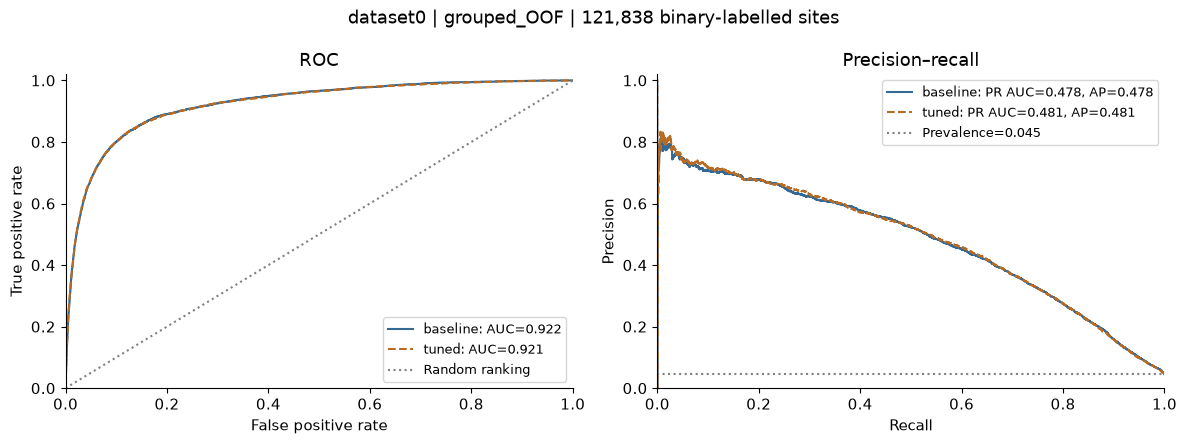

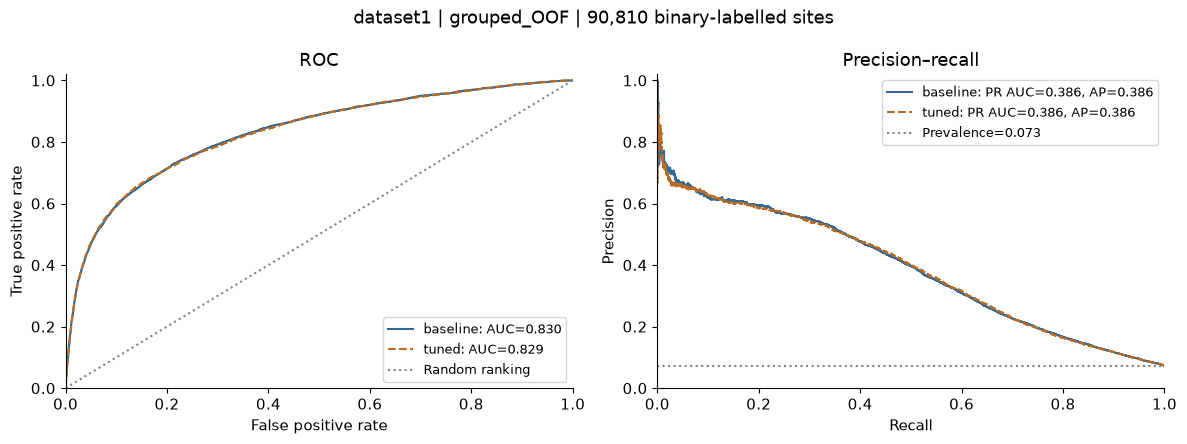

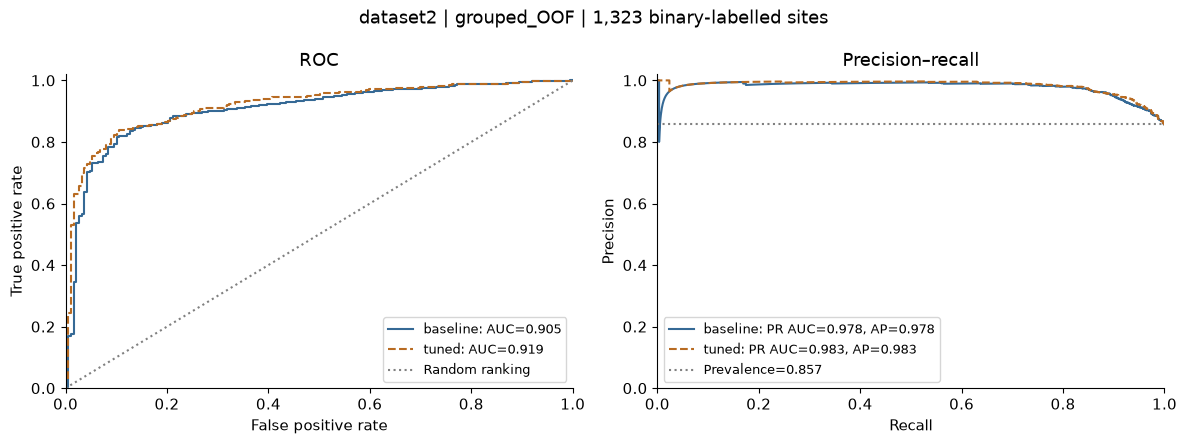

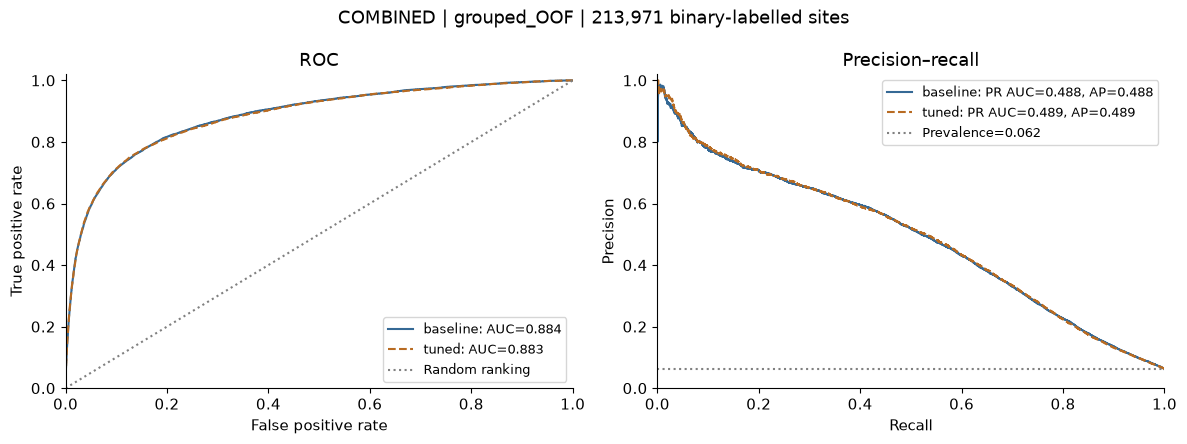

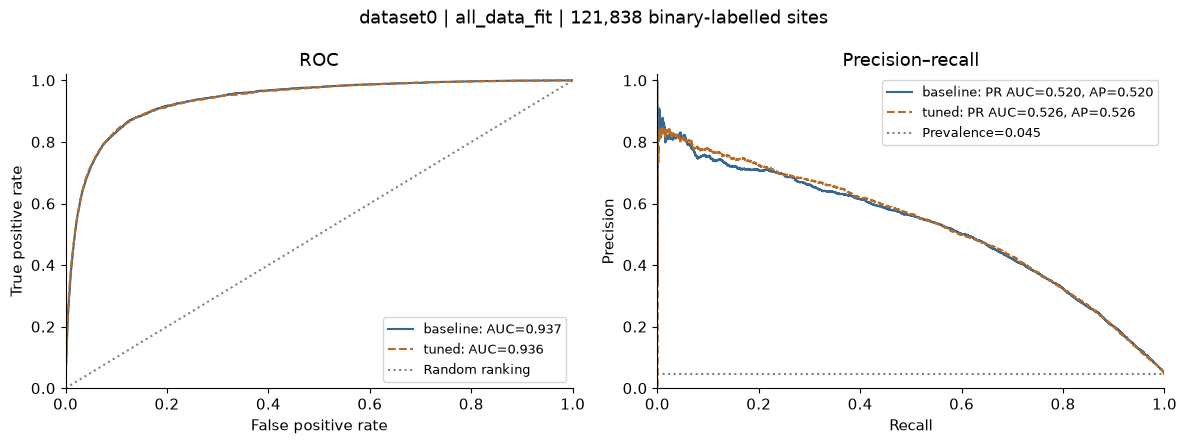

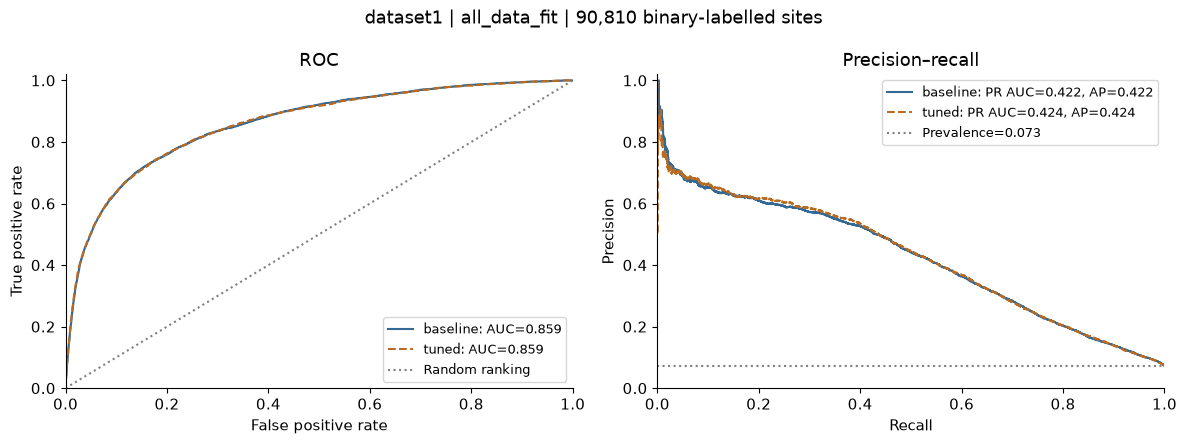

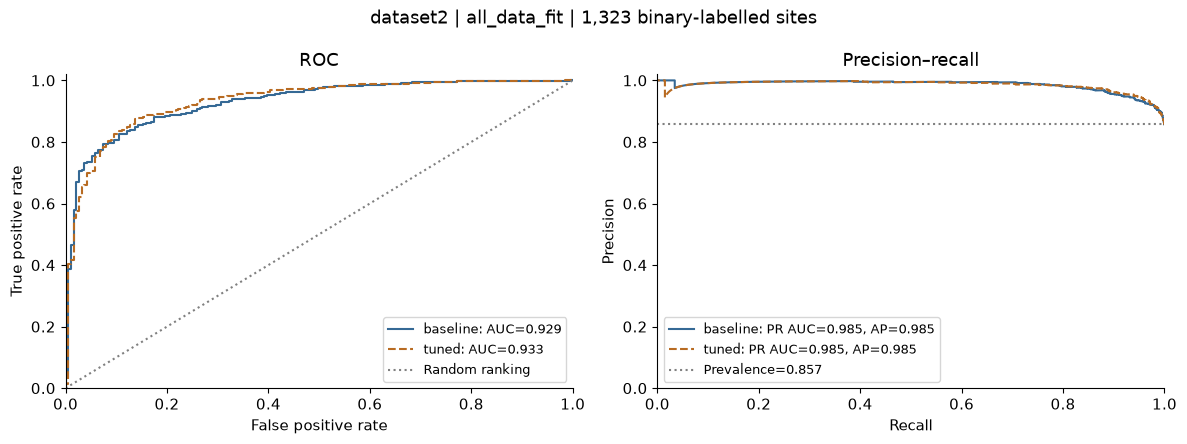

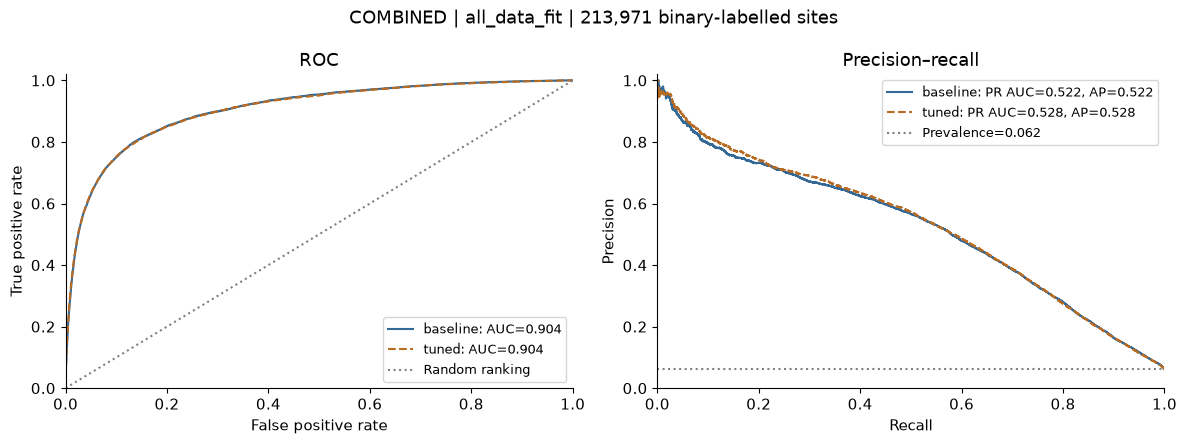

In [25]:
def plot_model_comparison(evaluation):
    if evaluation=='grouped_OOF':
        frame=train_df
        predictions={'baseline':baseline_cv['oof']}
        if tuned_cv is not None: predictions['tuned']=tuned_cv['oof']
    else:
        frame=pd.concat(dataset_tables.values(),ignore_index=True)
        predictions={'baseline':np.concatenate([baseline_fit['scores'][n] for n in dataset_tables])}
        if tuned_fit is not None: predictions['tuned']=np.concatenate([tuned_fit['scores'][n] for n in dataset_tables])
    for name in [c['dataset_id'] for c in DATASETS]+['COMBINED']:
        mask=frame.label.notna().to_numpy()
        if name!='COMBINED': mask &= frame.dataset_id.eq(name).to_numpy()
        y=frame.loc[mask,'label'].to_numpy(dtype=int)
        if len(np.unique(y))<2: continue
        fig,axes=plt.subplots(1,2,figsize=(12,4.5))
        for model_name,scores in predictions.items():
            s=scores[mask]; m=metric_row(y,s)
            colour,style=('#356995','-') if model_name=='baseline' else ('#b86b22','--')
            fpr,tpr,_=roc_curve(y,s); precision,recall,_=precision_recall_curve(y,s)
            axes[0].plot(fpr,tpr,color=colour,linestyle=style,label=f'{model_name}: AUC={m["ROC_AUC"]:.3f}')
            axes[1].plot(recall,precision,color=colour,linestyle=style,label=f'{model_name}: PR AUC={m["PR_AUC_trapezoidal"]:.3f}, AP={m["average_precision"]:.3f}')
        axes[0].plot([0,1],[0,1],':',color='gray',label='Random ranking')
        axes[1].axhline(y.mean(),linestyle=':',color='gray',label=f'Prevalence={y.mean():.3f}')
        axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC')
        axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall')
        for ax in axes: ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend(fontsize=9)
        fig.suptitle(f'{name} | {evaluation} | {len(y):,} binary-labelled sites')
        fig.tight_layout(); fig.savefig(RUN_DIR/f'{evaluation}_{name}_curves.png',dpi=150,bbox_inches='tight')
        plt.show(); plt.close(fig)

plot_model_comparison('grouped_OOF')
plot_model_comparison('all_data_fit')

## 13. Save the selected model and one CSV per input dataset
The `selected/predictions` folder is the final handoff. It contains `<dataset_id>_predictions.csv` for **every entry** in `DATASETS`, including dataset 2, whose binary labels also contribute to training and evaluation. Each file covers its own original JSON keys; files are not merged into a single submission. `COMBINED` is an evaluation table row.

Separate `*_prediction_audit.csv` files record the fallback sites; do not submit those as prediction files. Review every fallback count. Baseline and tuned prediction files remain in their own experiment directories. Model and preprocessing must be kept together.

In [26]:
selected_dir=RUN_DIR/'selected'; selected_dir.mkdir(exist_ok=False)
for filename in ['model.pt','preprocessing.joblib','config.json']:
    shutil.copy2(RUN_DIR/selected_name/filename,selected_dir/filename)
shutil.copytree(RUN_DIR/selected_name/'predictions',selected_dir/'predictions')
chosen_fit=baseline_fit if selected_name=='baseline' else tuned_fit
export_summary=pd.DataFrame(chosen_fit['exports'])
export_summary['file']=[str(selected_dir/'predictions'/Path(p).name) for p in export_summary.file]
export_summary.to_csv(selected_dir/'export_summary.csv',index=False)
display(export_summary)

def sha256_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as handle:
        for block in iter(lambda:handle.read(1024*1024),b''): h.update(block)
    return h.hexdigest()
file_provenance={}
for name,paths in input_paths.items():
    file_provenance[name]={role:dict(path=path,sha256=sha256_file(Path(path)))
                          for role,path in paths.items() if path is not None}
manifest=dict(created_utc=datetime.now(timezone.utc).isoformat(),selected_model=selected_name,
    selection_rule='mean fold PR_AUC_trapezoidal, then mean fold ROC_AUC; exact tie retains baseline',
    seed=SEED,n_folds=N_FOLDS,threshold=THRESHOLD,baseline_config=BASE_CONFIG,
    tuned_config=tuned_cv['config'] if tuned_cv else None,search_space=SEARCH_SPACE,
    run_tuning=RUN_TUNING,n_trials=N_TRIALS,grouping=grouping_summary,
    qc_fallback=QC_FALLBACK,training_rows=len(train_df),training_positive_fraction=float(train_df.label.mean()),
    input_paths=file_provenance,cleaning_manifests=cleaning_manifests,
    packages={p:importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','torch','matplotlib','joblib']},
    python=sys.version,device=str(DEVICE),
    limitations=['All-data-fit scores reuse training rows.',
                 'Tuned CV scores reuse folds involved in selection; no untouched test or nested CV.',
                 'Evaluation of fraction-derived binary labels reflects the conversion rule recorded by the cleaner, not fraction prediction.',
                 'Unknown gene annotations use transcript grouping; no complete gene-disjoint claim.',
                 'QC fallback scores are audited and excluded from model evaluation.'])
(RUN_DIR/'run_manifest.json').write_text(json.dumps(manifest,indent=2,default=str))
print('Selected prediction CSVs:',selected_dir/'predictions')
print('All experiment tables:',RUN_DIR)

,dataset_id,file,rows,fallback_rows
0,dataset0,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...,121838,0
1,dataset1,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...,90810,0
2,dataset2,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...,1323,0


Selected prediction CSVs: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\rnn_output\20261006T234635_511867Z\selected\predictions
All experiment tables: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\outputs\rnn_output\20261006T234635_511867Z


## 14. Reload the model later and predict another cleaned dataset
Run Sections 1, 2, 3's feature-definition cell, 5 and 6 to define imports, tensor ordering, preprocessing and the model before using this example. Set `saved_dir` to the selected model directory from a completed run. Loading `joblib` files is appropriate only for artifacts you created or otherwise trust.

For a new raw JSON, first run the same cleaning notebook, then provide its full cleaning output. This notebook operates on cleaned summaries. The final project separately requires executable raw-JSON training/prediction scripts and benchmarking against m6Anet; those are not replaced by this notebook.

In [27]:
# Example: uncomment after editing the paths.
# saved_dir = Path('/path/to/completed/run/selected')
# checkpoint = torch.load(saved_dir/'model.pt', map_location='cpu', weights_only=True)
# reloaded = SiteGRU(checkpoint['config']['hidden_size'], checkpoint['config']['dropout']).to(DEVICE)
# reloaded.load_state_dict(checkpoint['state_dict'])
# preprocessing = joblib.load(saved_dir/'preprocessing.joblib')
# new_sites = pd.read_csv('/path/to/new/clean_signal_sites.csv.gz', dtype={'transcript_id': str})
# validate_features(new_sites)
# seq, aux = transform(new_sites, preprocessing)
# scores = predict_scores(reloaded, seq, aux, PREDICT_BATCH_SIZE)
# predictions = new_sites[KEY].copy(); predictions['score'] = scores.astype(float)
# predictions.to_csv('/path/to/new_clean_site_predictions.csv', index=False)
# This short example covers clean sites only. Use Section 8's raw-key verification
# and explicit QC fallback policy to produce complete original-key submissions.

## 15. Checks, interpretation and troubleshooting
- **Paths:** copy the cleaner's run directory and check actual spelling/capitalisation on Ronin. Do not upload a Windows `.venv`; create a Python environment on Ronin.
- **Dataset 2:** use the cleaner-generated binary `label` column in `clean_labeled_sites.csv.gz`. Its original fraction is ignored in training and evaluation. If that file is empty, point to a run that applied your binary conversion rule; this notebook does not select a cutoff for you.
- **One-class file:** it can contribute training rows when pooled data has both classes. Its individual AUCs are unavailable; pooled AUC may still be computed.
- **Failed fold class check:** inspect group/class counts; reduce `N_FOLDS` if necessary. Do not search random seeds for better scores.
- **Memory/runtime:** reduce batch size and `N_TRIALS`; use `RUN_TUNING=False` for the first baseline run. Compressed CSV sizes are not RAM requirements. Inputs and the pooled training table stay in memory; mini-batches limit GPU memory, not total RAM.
- **Results:** positive deltas describe observed increases, not independent proof of improvement. Do not report training-set AUC as held-out test performance. Check per-dataset scores alongside the pooled row.
- **Submission coverage:** use `selected/predictions/*_predictions.csv`, with exactly three columns and one file per source. Inspect the fallback audits before submission.
- **GitHub:** keep data/model runs outside the repository, commit code/documentation, and clear notebook output cells before sharing if they contain private paths/data.

### Sources and authoring validation
Based on the three supplied files: `handout_project2_RNAModifications.html`, `m6a_rnn_training.ipynb`, and `m6a_clean_multiple_datasets.ipynb`.

API references: [PyTorch GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html), [weighted BCE loss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html), [scikit-learn precision–recall curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html), [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

**Real datasets were not supplied.** The notebook's structure, syntax and a small synthetic end-to-end run are checked during authoring; no real-data model performance is claimed. Run **Restart Kernel → Run All** with your actual cleaned files, then review manifests, fold checks, scores and fallback audits. Record AI assistance and verified corrections as the handout requires.